# Figure 5 — v2 selected models and W05 crystal examples



In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "plagnetplus").is_dir())
sys.path.insert(0, str(ROOT / "src"))
OUTPUT = ROOT / "figures" / "final"
OUTPUT.mkdir(parents=True, exist_ok=True)

import os
import pandas as pd
from IPython.display import display
from plagnetplus.evaluation.embedding_io import load_embedding_bundle
from plagnetplus.figures.image_grids import build_validation_pca_frame, plot_pca_extremes, plot_representative_clusters

DATA_ROOT = Path(os.environ["PNP_DATA_ROOT"])
RUNS_ROOT = Path(os.environ["PNP_RUNS_ROOT"])
REFERENCE = ROOT / "results/reference"
metrics = pd.read_csv(REFERENCE / "v2_selected/selected_model_metrics.csv")
display(metrics.style.format(precision=4, na_rep="—"))

from IPython.display import Image as IPyImage, Markdown

def show_saved_figure(path):
    path = Path(path)
    display(Markdown(f"**Saved figure:** `{path}`"))
    display(IPyImage(filename=str(path)))


,Model,Median silhouette score,Stability ARI,FCT cross-sample P@10,Location-probe macro-F1,Source-image enrichment@10,Effective rank,GPU hours,Selected k,Status
0,SimSiam S10 v2,0.1855,0.5678,0.1218,0.5980,2.5632,5.5739,7.5420,50.0000,complete
1,SwAV W05 v2,0.3139,0.8672,0.2209,0.4616,2.6022,35.4945,7.4184,50.0000,complete
2,SwAV W12 v2,0.3095,0.6990,0.2852,0.4526,2.5341,42.9081,7.4433,50.0000,complete


**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_05a_w05_representative_clusters.png`

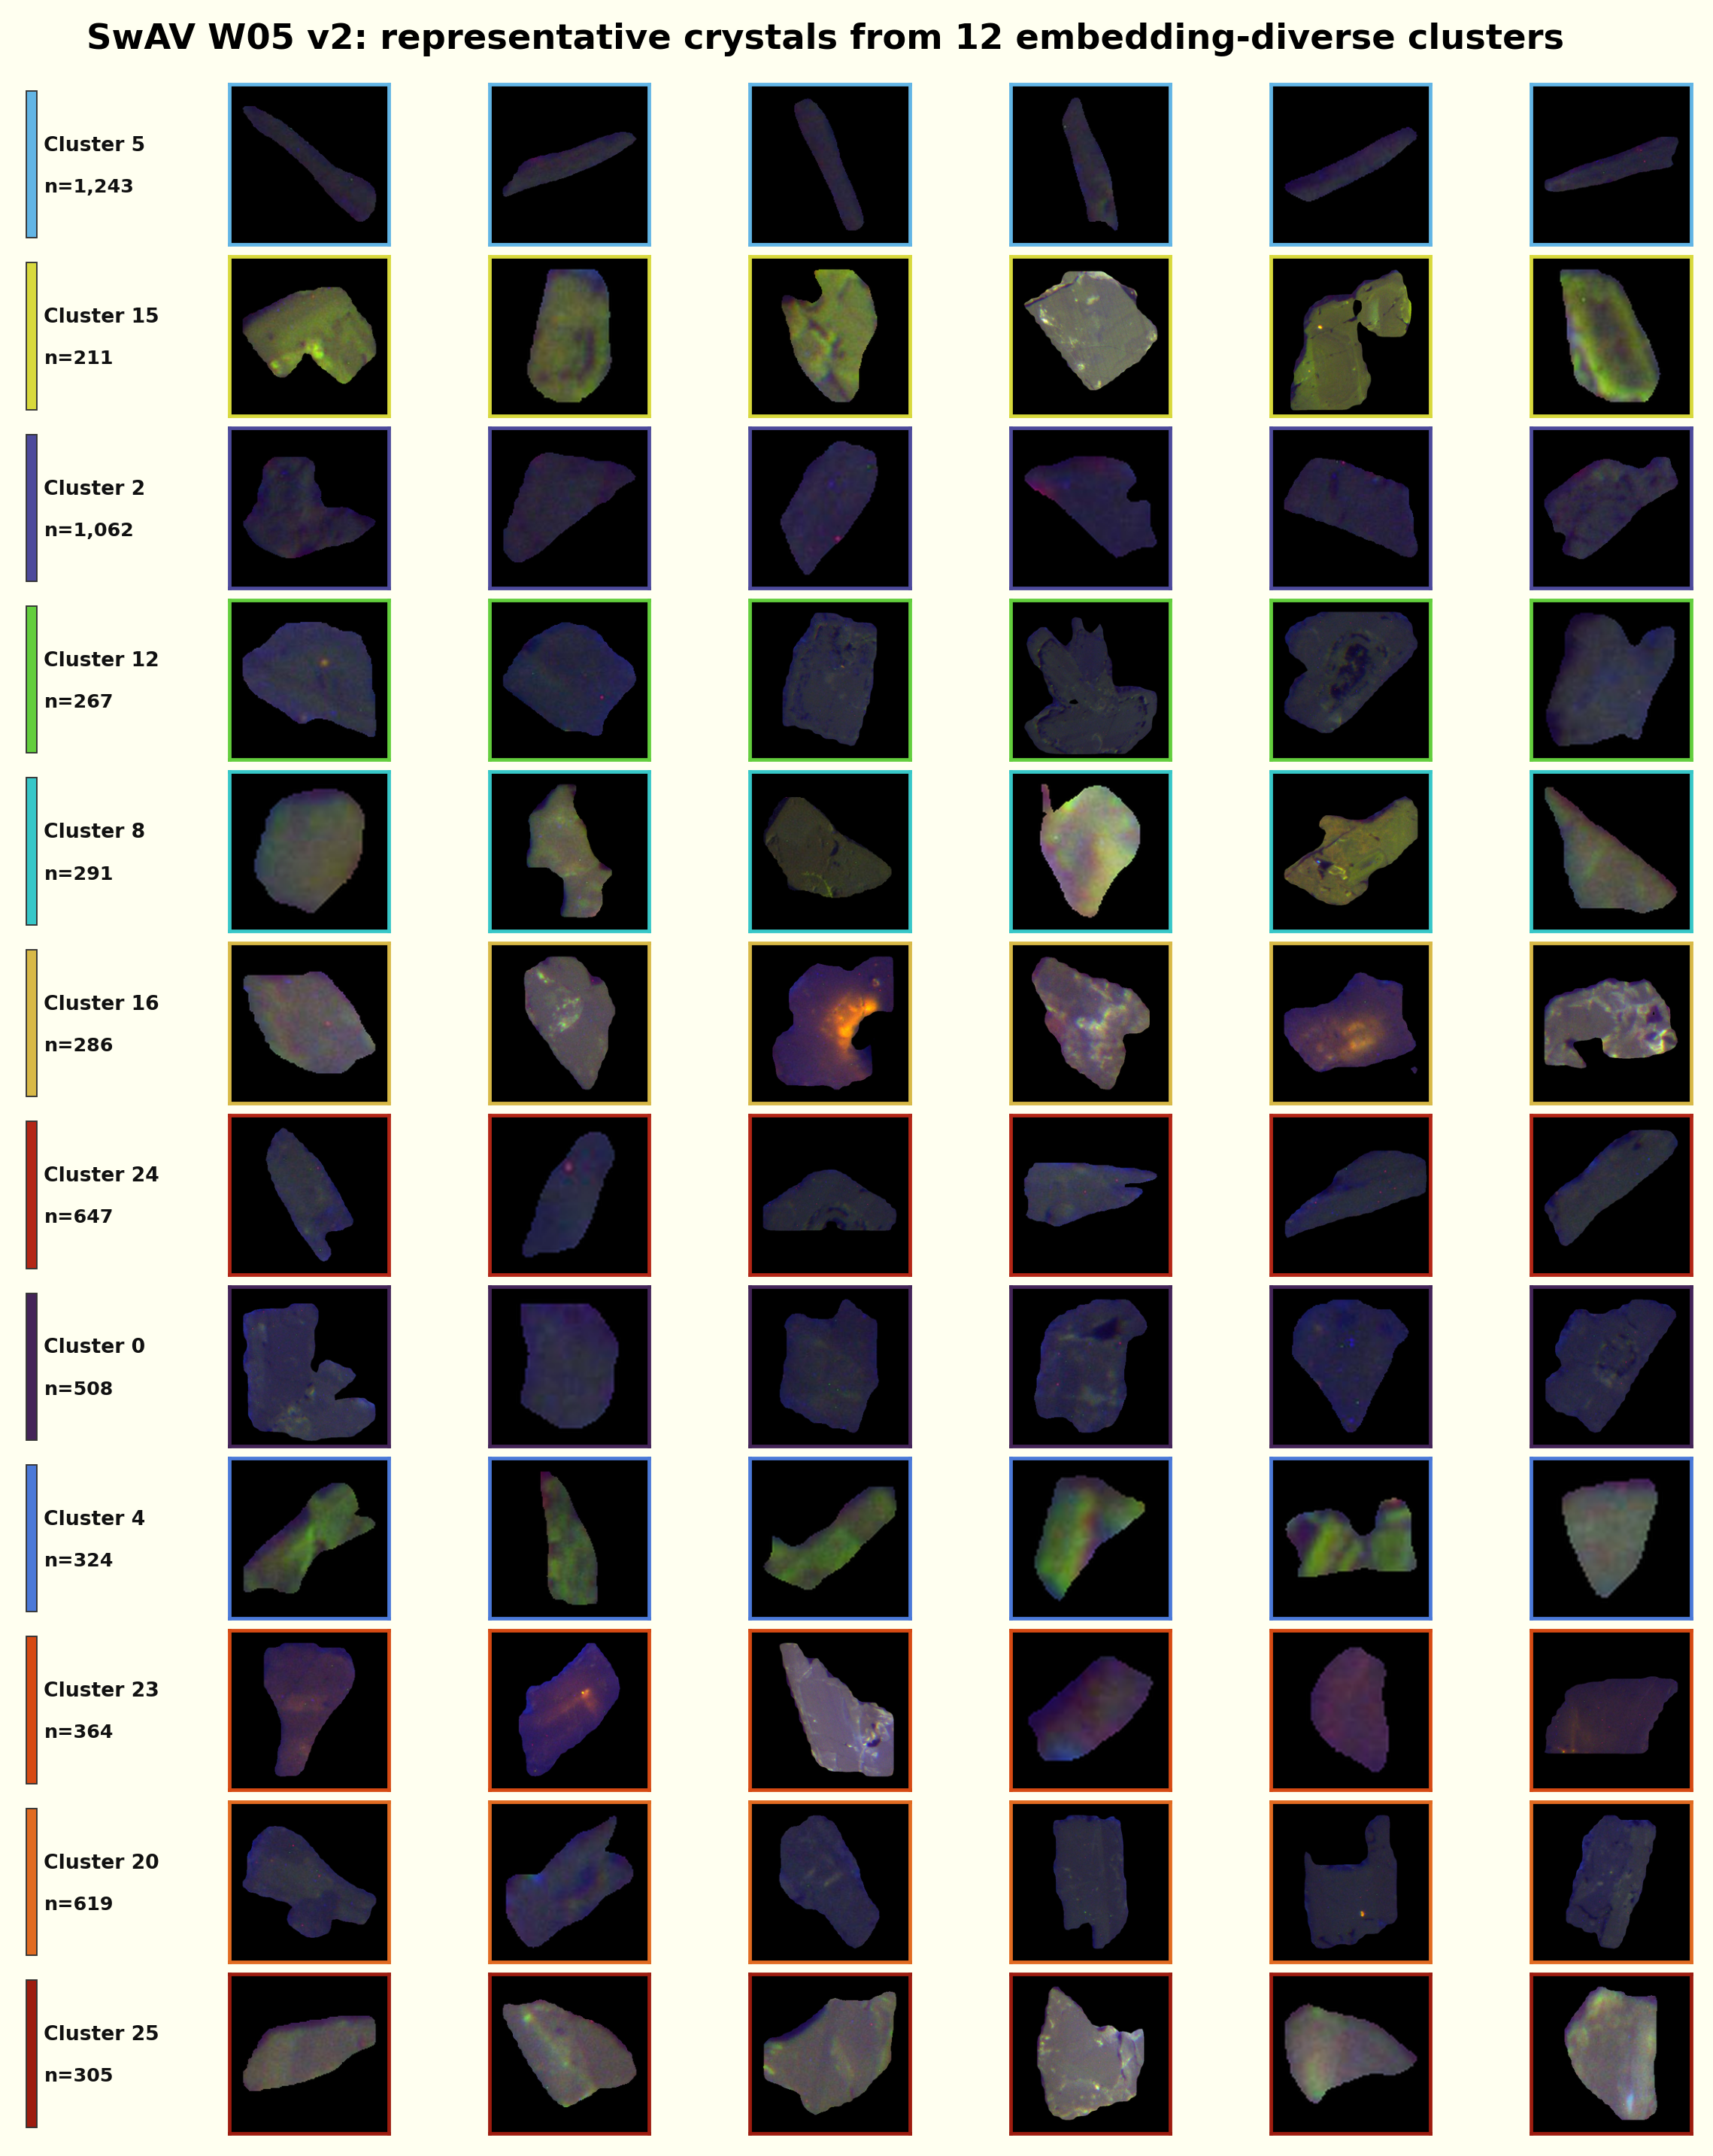

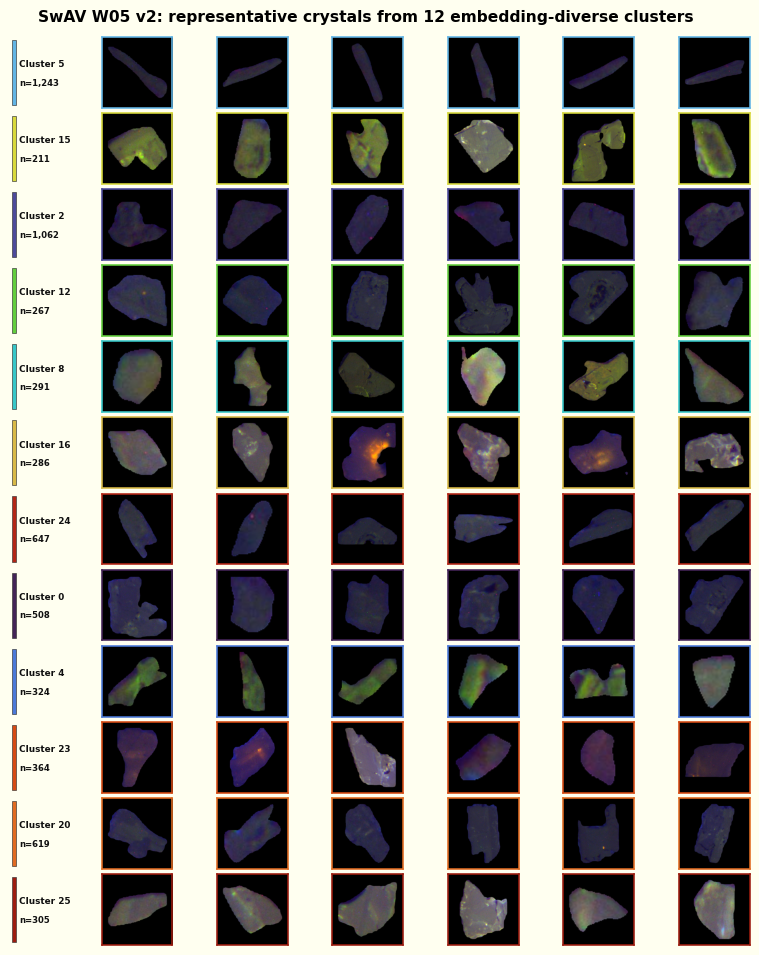

In [2]:
clusters = pd.read_csv(REFERENCE / "figure_05/w05_cluster_examples_a4_selection.csv")
figure = plot_representative_clusters(
    clusters,
    data_root=DATA_ROOT,
    title="SwAV W05 v2: representative crystals from 12 embedding-diverse clusters",
)
out_path = OUTPUT / "figure_05a_w05_representative_clusters.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)


**Saved figure:** `/home/ars223/MSc-GEMS/IRP26/pnp_staging/figures/final/figure_05b_w05_pca_extremes.png`

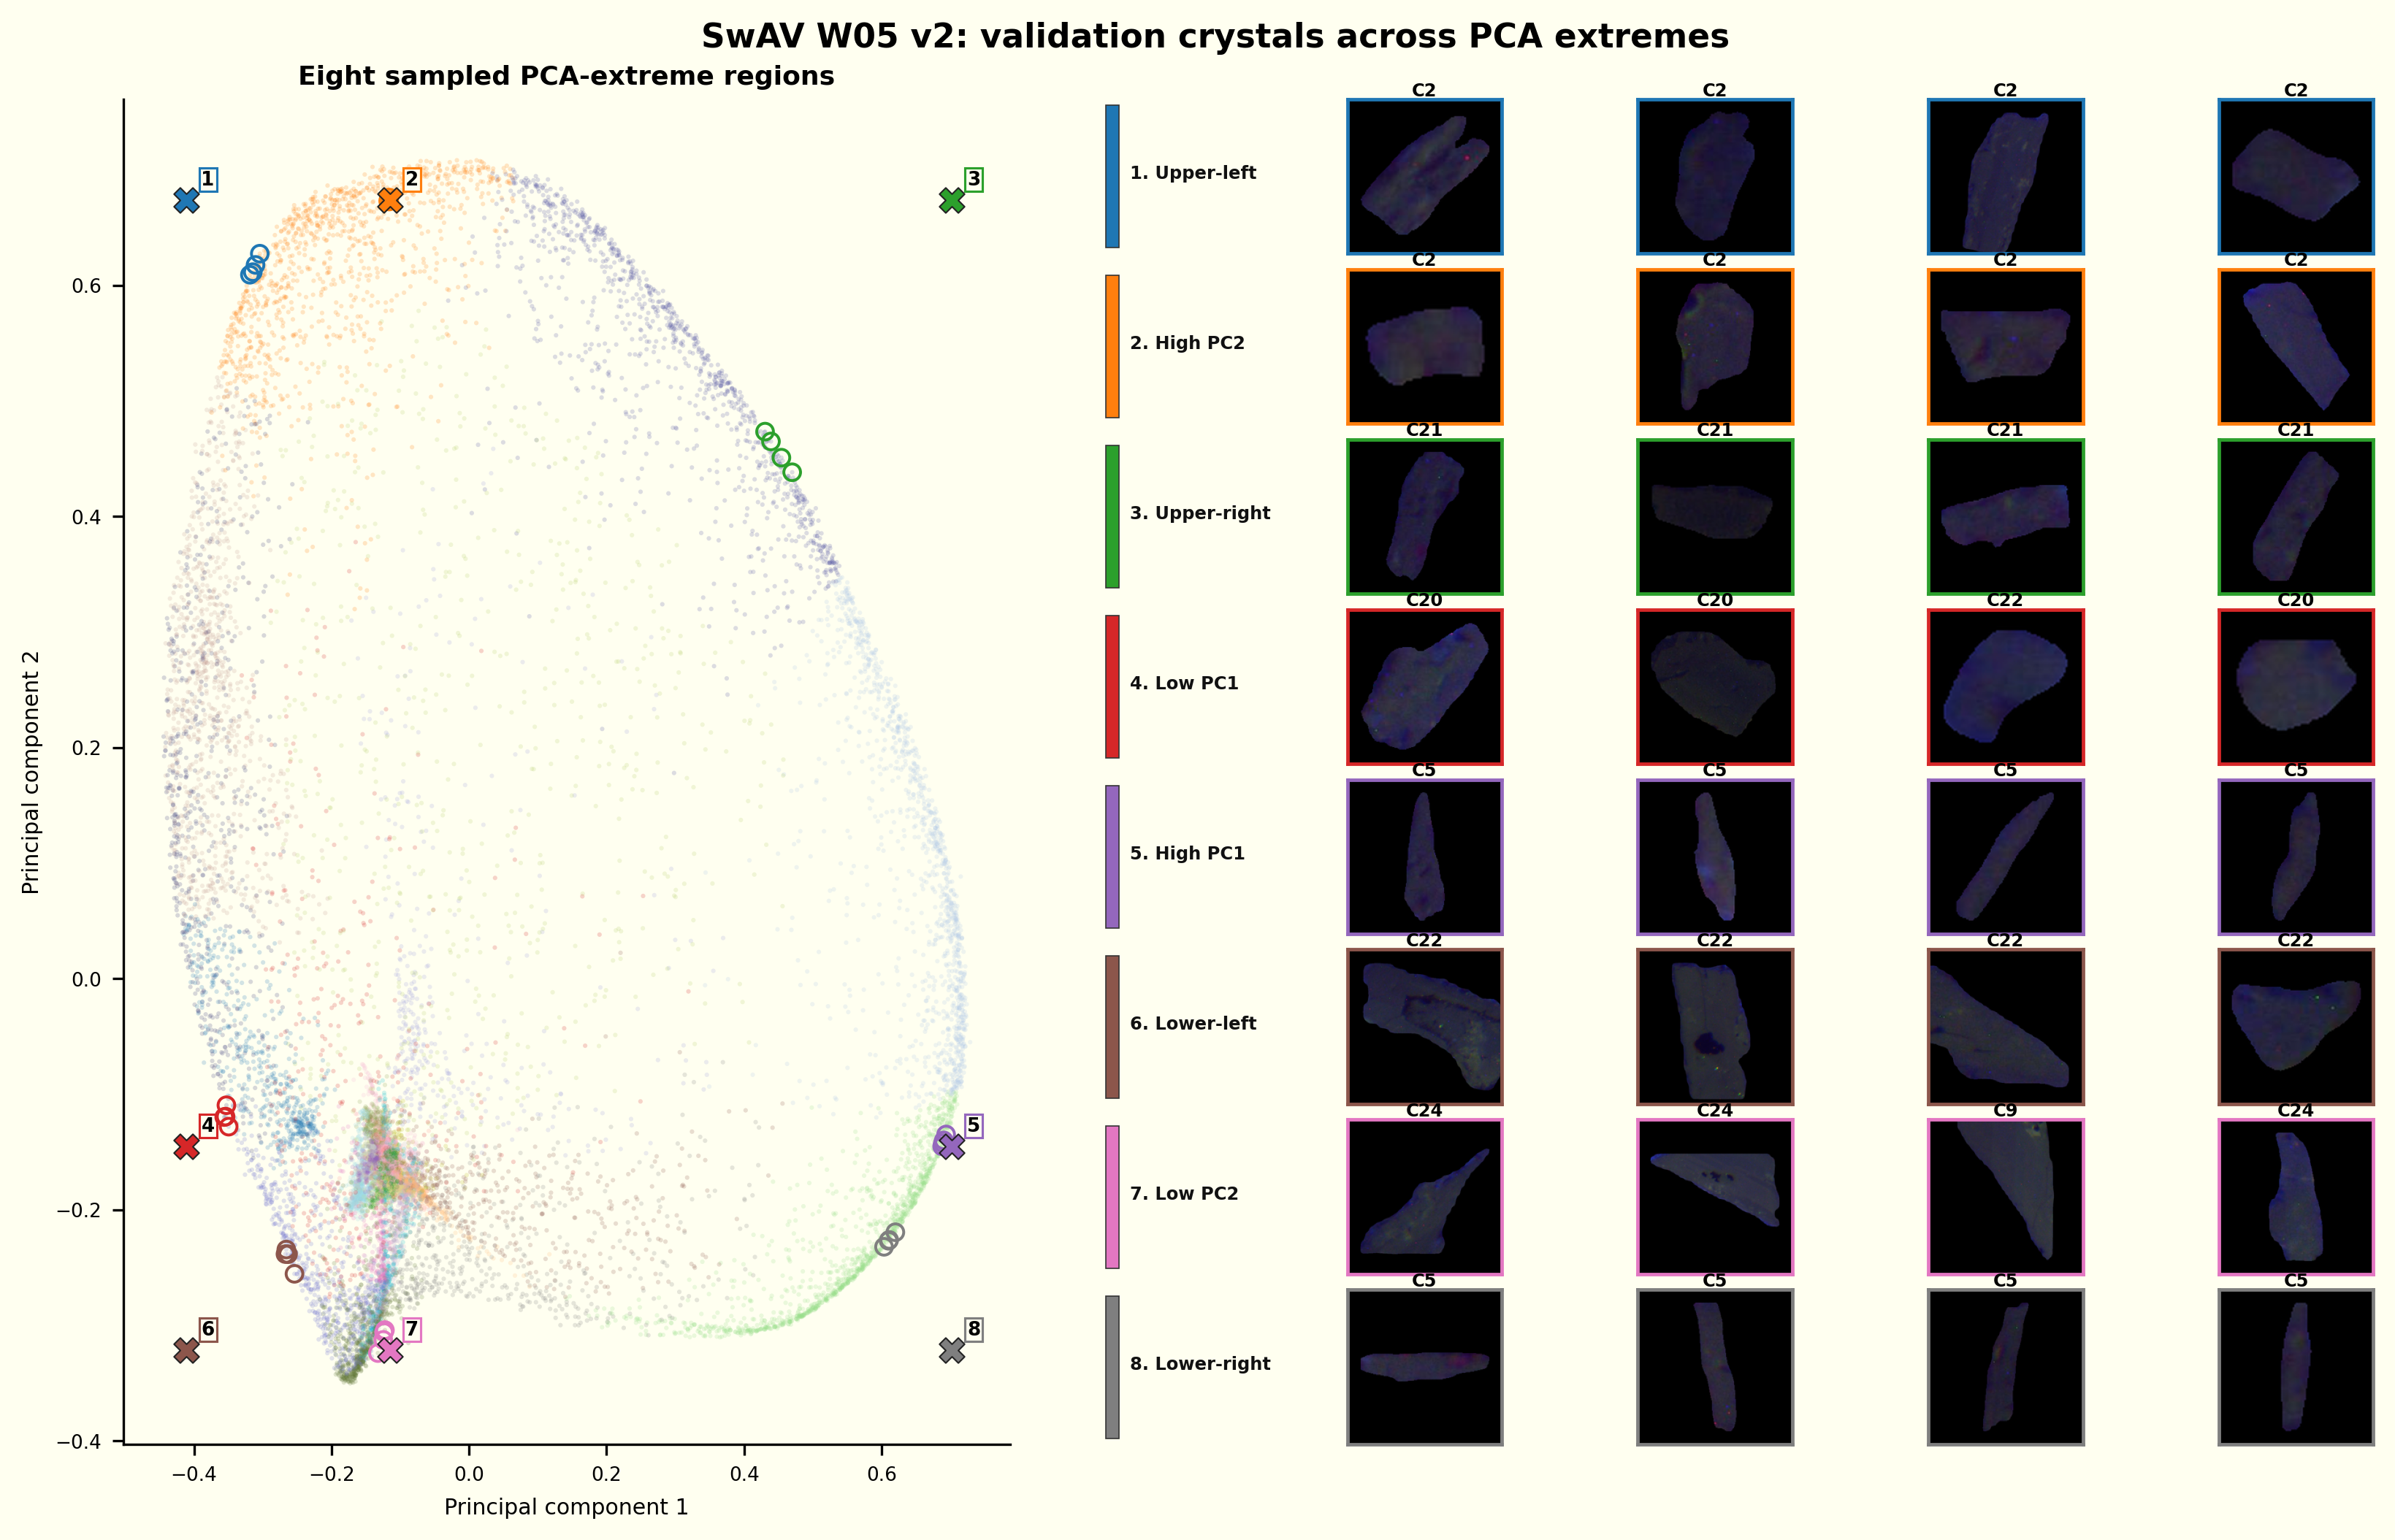

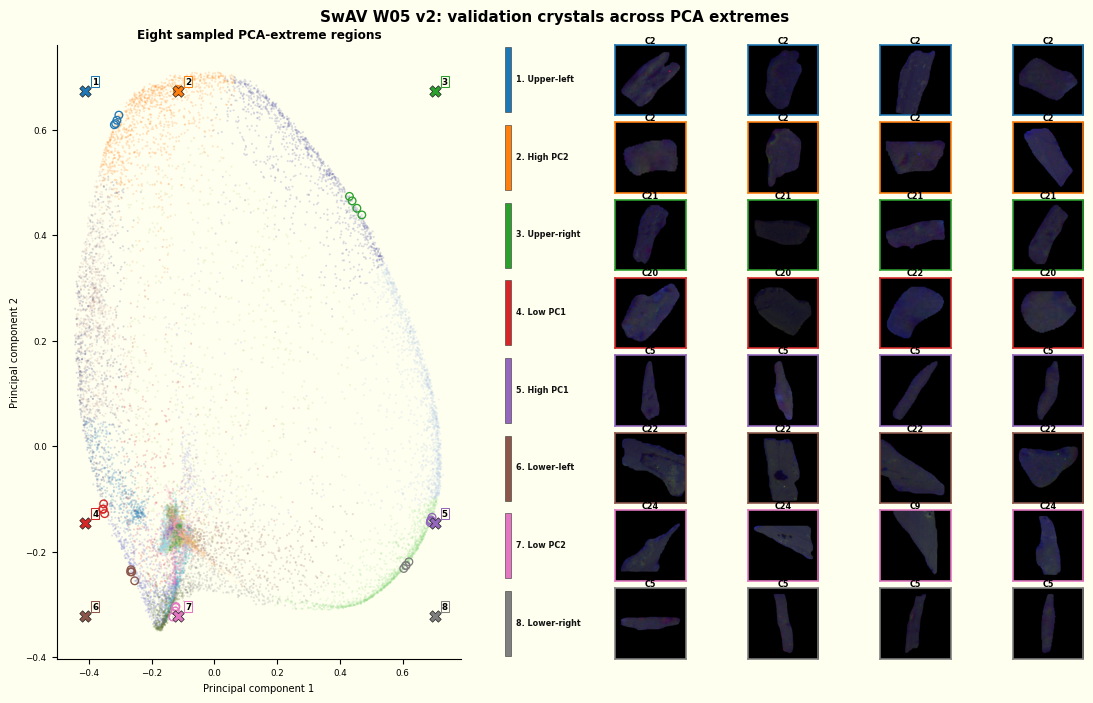

In [3]:
extremes = pd.read_csv(REFERENCE / "figure_05/pca_extreme_sample_selections.csv")
extremes = extremes.loc[extremes.Model == "SwAV W05 v2"]
region_summary = pd.read_csv(REFERENCE / "figure_05/pca_extreme_region_summary.csv")
region_summary = region_summary.loc[region_summary.Model == "SwAV W05 v2"]
assignments = pd.read_csv(REFERENCE / "figure_05/w05_elbow_k27_assignments.csv")
W05_RUN = RUNS_ROOT / "hpc/v2/selected/swav_w05_lr0p3_p250_t0p1_eps0p05_e100_seed42_v2"
bundle = load_embedding_bundle(W05_RUN / "embeddings/validation_backbone_embeddings.npz")
pca_points = build_validation_pca_frame(bundle.features, bundle.crystal_ids, assignments, extremes)
figure = plot_pca_extremes(
    extremes,
    region_summary,
    data_root=DATA_ROOT,
    title="SwAV W05 v2: validation crystals across PCA extremes",
    pca_points=pca_points,
    images_per_group=4,
)
out_path = OUTPUT / "figure_05b_w05_pca_extremes.png"
figure.savefig(out_path, dpi=300)
show_saved_figure(out_path)
